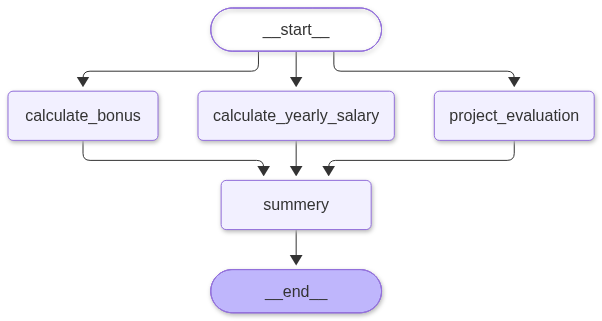

In [6]:
from langgraph.graph import StateGraph, START, END
from dotenv import load_dotenv
from typing import TypedDict

load_dotenv()


# Define State
class EmployeeState(TypedDict):
    employee_name: str
    monthly_salary: int
    working_days: int
    completed_projects: int
    yearly_salary: int
    bonus_amount: int
    project_status: str
    summary: str
    

# Create new node
def calculate_yearly_salary(state: EmployeeState) -> EmployeeState:
    yearly_salary = state['yearly_salary'] * 12
    state['yearly_salary'] = yearly_salary
    return state


def calculate_bonus(state: EmployeeState) -> EmployeeState:
    bonus_amount = state['yearly_salary'] * 2
    state['bonus_amount'] = bonus_amount
    return state


def project_evaluation(state: EmployeeState) -> EmployeeState:
    if state['completed_projects'] >= 5:
        status = 'Excellent'
    else:
        status = 'Average'
    state['project_status'] = status
    return state


def summary(state: EmployeeState) -> EmployeeState:
    summary_text = f"Employee {state['employee_name']} has a yearly salary of {state['yearly_salary']} and a ..."
    state['summary'] = summary_text
    return state


# Create graph
graph = StateGraph(EmployeeState)

# Add nodes
graph.add_node('calculate_yearly_salary', calculate_yearly_salary)
graph.add_node('calculate_bonus', calculate_bonus)
graph.add_node('project_evaluation', project_evaluation)
graph.add_node('summery', summary)

# Add Edges
graph.add_edge(START, 'calculate_yearly_salary')
graph.add_edge(START, 'calculate_bonus')
graph.add_edge(START, 'project_evaluation')

graph.add_edge('calculate_yearly_salary', 'summery')
graph.add_edge('calculate_bonus', 'summery')
graph.add_edge('project_evaluation', 'summery')

graph.add_edge('summery', END)


workflow = graph.compile()

workflow


